/var/folders/h5/1rb1tj8x0vs85cxtszq9_hdm0000gn/T/ipykernel_77671/916719089.py:82: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


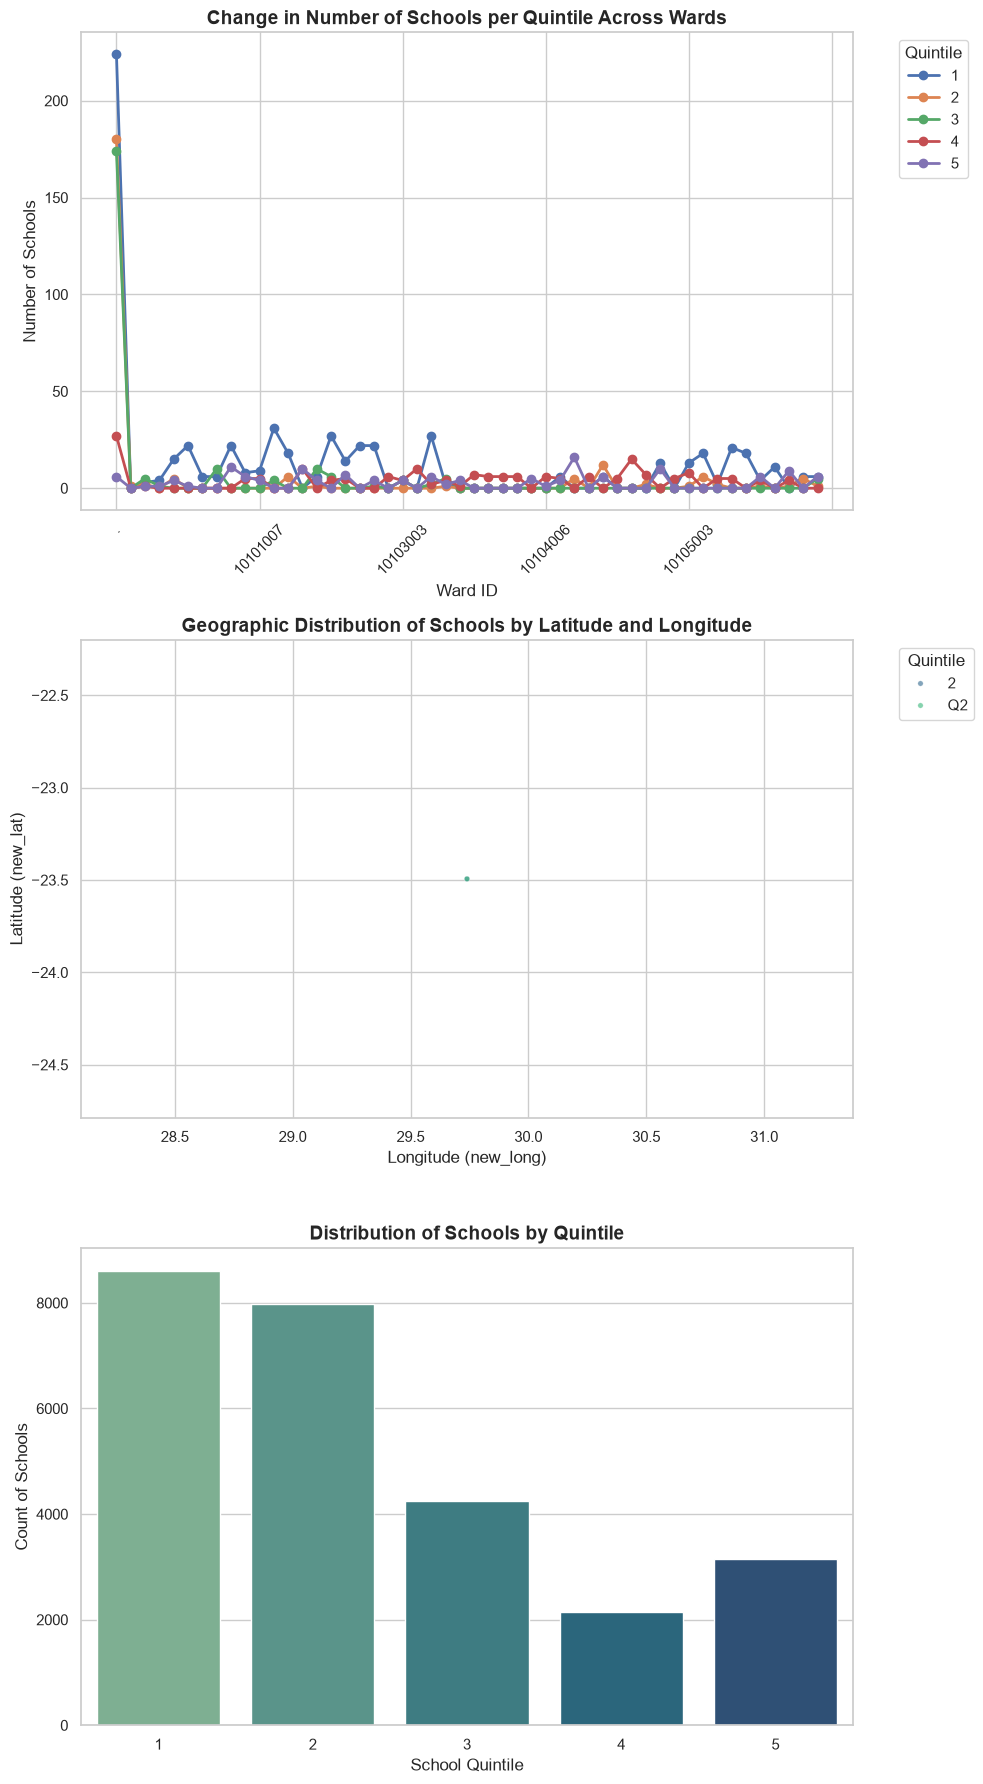

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load the CSV file (saved in the same folder as the notebook)
# Using latin1 encoding and python engine to handle special characters and formatting quirks
df = pd.read_csv(
    "School_Data_CSV.csv", encoding="latin1", engine="python", on_bad_lines="skip"
)

# 2. Clean column names (remove any trailing semicolons or whitespace)
df.columns = df.columns.str.replace(";", "").str.strip()

# 3. Data Preparation and Cleaning
# Clean latitude and longitude columns by coercing non-numeric values (like 'NA') to NaN
df["new_long"] = pd.to_numeric(df["new_long"], errors="coerce")
df["new_lat"] = pd.to_numeric(df["new_lat"], errors="coerce")

# Clean quintile column (remove whitespace and filter out invalid/missing categories)
df["quintile"] = df["quintile"].astype(str).str.strip()
# Drop rows with missing/invalid quintiles or coordinates where necessary
df_clean = df.dropna(subset=["quintile", "ward_id"]).copy()

# Filter out non-standard quintile entries if needed (e.g., 'NOT APPLICABLE', '.', etc.)
valid_quintiles = ["1", "2", "3", "4", "5"]
df_quintile = df_clean[df_clean["quintile"].isin(valid_quintiles)].copy()
df_quintile["quintile"] = df_quintile["quintile"].astype(int)

# Set up the plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

# --- Visualization A: Line Plot ---
# Group by ward_id and quintile to count schools, then unstack to get quintiles as columns
ward_quintile_counts = (
    df_quintile.groupby(["ward_id", "quintile"]).size().unstack(fill_value=0)
)
# Sort by ward_id or take a representative sample of wards for clarity if dataset is large
ward_quintile_counts.head(50).plot(
    kind="line", marker="o", ax=axes[0], linewidth=2
)
axes[0].set_title(
    "Change in Number of Schools per Quintile Across Wards",
    fontsize=14,
    fontweight="bold",
)
axes[0].set_xlabel("Ward ID", fontsize=12)
axes[0].set_ylabel("Number of Schools", fontsize=12)
axes[0].legend(title="Quintile", bbox_to_anchor=(1.05, 1), loc="upper left")
axes[0].tick_params(axis="x", rotation=45)

# --- Visualization B: Scatter Plot ---
# Filter valid geographic coordinates within South Africa's approximate bounding box
df_geo = df.dropna(subset=["new_long", "new_lat"])
df_geo = df_geo[
    (df_geo["new_long"] >= 16)
    & (df_geo["new_long"] <= 33)
    & (df_geo["new_lat"] >= -35)
    & (df_geo["new_lat"] <= -22)
]

sns.scatterplot(
    data=df_geo,
    x="new_long",
    y="new_lat",
    hue="quintile",
    palette="viridis",
    alpha=0.6,
    s=15,
    ax=axes[1],
)
axes[1].set_title(
    "Geographic Distribution of Schools by Latitude and Longitude",
    fontsize=14,
    fontweight="bold",
)
axes[1].set_xlabel("Longitude (new_long)", fontsize=12)
axes[1].set_ylabel("Latitude (new_lat)", fontsize=12)
axes[1].legend(title="Quintile", bbox_to_anchor=(1.05, 1), loc="upper left")

# --- Visualization C: Histogram ---
sns.countplot(
    data=df_quintile,
    x="quintile",
    order=[1, 2, 3, 4, 5],
    palette="crest",
    ax=axes[2],
)
axes[2].set_title(
    "Distribution of Schools by Quintile", fontsize=14, fontweight="bold"
)
axes[2].set_xlabel("School Quintile", fontsize=12)
axes[2].set_ylabel("Count of Schools", fontsize=12)

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()